# Teste 1 — Inteligência Artificial
## Regressão para estimativa de valor de empréstimo

**Objetivo:** construir um modelo de Aprendizado de Máquina Supervisionado capaz de estimar o valor de empréstimo oferecido a um novo cliente.

> Observação: `historico_pagamentos` representa a porcentagem de pagamentos realizados em dia, variando de 0 a 100.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Etapa 1 — Carregar os dados

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# O CSV deve estar na mesma pasta do notebook
df = pd.read_csv("base_credito.csv")

# Apresentar a tabela carregada
display(df.head(10))

print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54
5,40,5842.28,708,67.78,26522.53
6,40,3993.85,847,84.37,39544.67
7,35,4933.07,630,100.00,26588.60
8,56,6105.73,669,93.38,25099.70
9,44,4430.53,637,93.11,24923.26


Quantidade de linhas: 50000
Quantidade de colunas: 5


## Etapa 2 — Conhecer os dados

As variáveis de entrada são:
- **idade:** idade do cliente, em anos.
- **renda_mensal:** renda mensal do cliente.
- **score_credito:** pontuação de crédito do cliente.
- **historico_pagamentos:** porcentagem de pagamentos realizados em dia (0 a 100).

A variável que deverá ser prevista é:
- **valor_emprestimo:** valor do empréstimo aprovado para o cliente.

Os tipos de dados podem ser verificados abaixo.


In [13]:
print("Tipos de dados:")
display(df.dtypes.to_frame("tipo"))

print("\nInformações estatísticas:")
display(df.describe())

print("\nValores ausentes:")
display(df.isnull().sum().to_frame("quantidade"))

print("\nDuplicatas:")
print(df.duplicated().sum())


Tipos de dados:


,tipo
idade,int64
renda_mensal,float64
score_credito,int64
historico_pagamentos,float64
valor_emprestimo,float64



Informações estatísticas:


,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,40.08028,7542.184144,649.581780,81.836888,31736.158491
std,10.77612,4524.255313,84.648363,11.209708,14456.325322
min,18.00000,1500.000000,300.000000,16.210000,1000.000000
25%,33.00000,4463.347500,592.000000,75.160000,22018.212500
50%,40.00000,6452.295000,650.000000,83.720000,29039.420000
75%,47.00000,9395.700000,707.000000,90.330000,38275.932500
max,70.00000,50000.000000,850.000000,100.000000,150000.000000



Valores ausentes:


,quantidade
idade,0
renda_mensal,0
score_credito,0
historico_pagamentos,0
valor_emprestimo,0



Duplicatas:
0


## Etapa 3 — Analisar os dados

Um gráfico de dispersão entre renda mensal e valor do empréstimo ajuda a visualizar a relação entre uma variável de entrada e a variável-alvo.

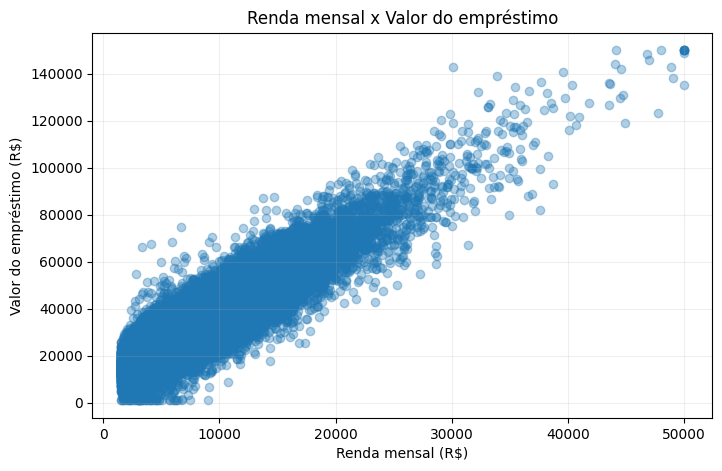

Correlação com o valor do empréstimo:


,valor_emprestimo
valor_emprestimo,1.000000
renda_mensal,0.886813
score_credito,0.358151
historico_pagamentos,0.076832
idade,0.040998


In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df["renda_mensal"], df["valor_emprestimo"], alpha=0.35)
plt.xlabel("Renda mensal (R$)")
plt.ylabel("Valor do empréstimo (R$)")
plt.title("Renda mensal x Valor do empréstimo")
plt.grid(alpha=0.2)
plt.show()

print("Correlação com o valor do empréstimo:")
display(df.corr(numeric_only=True)["valor_emprestimo"].sort_values(ascending=False))


**Interpretação:** observa-se uma relação positiva entre renda mensal e valor do empréstimo: em geral, clientes com maior renda tendem a apresentar valores de empréstimo maiores. A correlação deve ser interpretada como associação nos dados, e não como prova de causalidade.


## Etapa 4 — Preparar os dados

Será utilizada a divisão de **80% para treinamento e 20% para teste**.

In [7]:
from sklearn.model_selection import train_test_split

X = df[[
    "idade",
    "renda_mensal",
    "score_credito",
    "historico_pagamentos"
]]

y = df["valor_emprestimo"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print(f"Dados de treinamento: {len(X_train)} ({len(X_train)/len(X)*100:.0f}%)")
print(f"Dados de teste: {len(X_test)} ({len(X_test)/len(X)*100:.0f}%)")


Dados de treinamento: 40000 (80%)
Dados de teste: 10000 (20%)


## Etapa 5 — Treinar o modelo

Será utilizada **Regressão Linear** para prever o valor do empréstimo a partir das características do cliente.

In [8]:
from sklearn.linear_model import LinearRegression

# Criar o modelo
modelo = LinearRegression()

# Treinar o modelo
modelo.fit(X_train, y_train)

# Gerar previsões
y_pred = modelo.predict(X_test)

print("Modelo treinado com sucesso.")


Modelo treinado com sucesso.


### Coeficientes do modelo

In [9]:
coeficientes = pd.DataFrame({
    "variavel": X.columns,
    "coeficiente": modelo.coef_
})

display(coeficientes)
print(f"Intercepto: {modelo.intercept_:.2f}")


,variavel,coeficiente
0,idade,54.706246
1,renda_mensal,2.828448
2,score_credito,60.890564
3,historico_pagamentos,98.907289


Intercepto: -39439.69


## Etapa 6 — Avaliar o modelo

Serão utilizadas três métricas: **MAE**, **RMSE** e **R²**.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  (Erro Médio Absoluto): R$ {mae:,.2f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): R$ {rmse:,.2f}")
print(f"R²   (Coeficiente de Determinação): {r2:.4f}")

print("\nInterpretação:")
print(f"- MAE: em média, as previsões diferem dos valores reais em aproximadamente R$ {mae:,.2f}.")
print(f"- RMSE: penaliza erros maiores e ficou em aproximadamente R$ {rmse:,.2f}.")
print(f"- R²: o modelo explica aproximadamente {r2*100:.2f}% da variação observada no valor dos empréstimos.")


MAE  (Erro Médio Absoluto): R$ 2,985.94
RMSE (Raiz do Erro Quadrático Médio): R$ 4,014.17
R²   (Coeficiente de Determinação): 0.9223

Interpretação:
- MAE: em média, as previsões diferem dos valores reais em aproximadamente R$ 2,985.94.
- RMSE: penaliza erros maiores e ficou em aproximadamente R$ 4,014.17.
- R²: o modelo explica aproximadamente 92.23% da variação observada no valor dos empréstimos.


## Etapa 7 — Comparar valores reais e previstos

,Valor real,Valor previsto,Erro absoluto
0,22268.46,14806.34,7462.12
1,27457.59,29512.49,2054.90
2,25451.04,25840.74,389.70
3,23890.67,21077.52,2813.15
4,27754.95,27919.31,164.36
5,12544.92,14530.91,1985.99
6,28759.01,27385.97,1373.04
7,46454.49,41011.61,5442.88
8,43199.01,36525.09,6673.92
9,34051.39,35786.96,1735.57


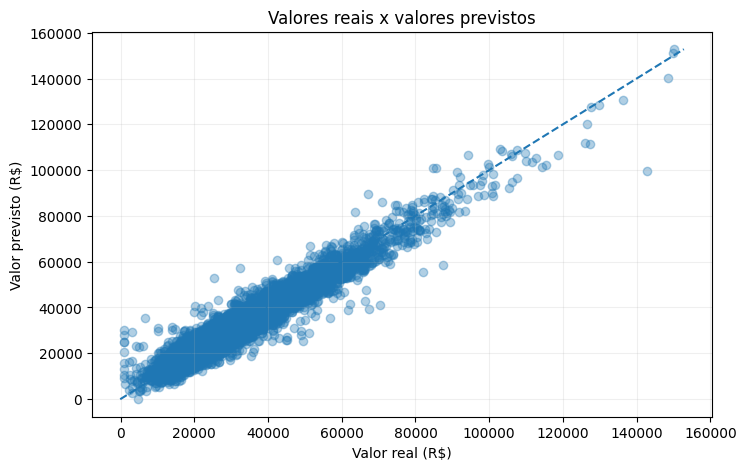

In [11]:
comparacao = pd.DataFrame({
    "Valor real": y_test.values,
    "Valor previsto": y_pred
})

comparacao["Erro absoluto"] = (
    comparacao["Valor real"] - comparacao["Valor previsto"]
).abs()

display(comparacao.head(10).round(2))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.35)
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], linestyle="--")
plt.xlabel("Valor real (R$)")
plt.ylabel("Valor previsto (R$)")
plt.title("Valores reais x valores previstos")
plt.grid(alpha=0.2)
plt.show()


**Análise:** quanto mais próximos os pontos estiverem da linha diagonal, mais próximas estão as previsões dos valores reais. A tabela permite observar exemplos individuais, enquanto o gráfico mostra o comportamento geral das previsões.


## Etapa 8 — Fazer uma previsão para um novo cliente

In [12]:
novo_cliente = pd.DataFrame({
    "idade": [35],
    "renda_mensal": [8000.00],
    "score_credito": [700],
    "historico_pagamentos": [90.00]
})

previsao = modelo.predict(novo_cliente)[0]

print("Características do novo cliente:")
display(novo_cliente)

print(f"Valor previsto do empréstimo: R$ {previsao:,.2f}")


Características do novo cliente:


,idade,renda_mensal,score_credito,historico_pagamentos
0,35,8000.0,700,90.0


Valor previsto do empréstimo: R$ 36,627.66


**Interpretação:** para esse cliente hipotético, o modelo estima um valor de empréstimo de aproximadamente o valor apresentado acima. Essa estimativa é uma previsão estatística baseada nos padrões encontrados na base histórica e não representa uma garantia de aprovação.


## Etapa 9 — Conclusão

O modelo de regressão pode ser utilizado para estimar valores de empréstimo a partir das características disponíveis na base. A adequação do modelo deve ser avaliada principalmente pelas métricas obtidas no conjunto de teste e pela proximidade entre os valores reais e previstos.

Entre as principais limitações estão:
- o modelo depende da qualidade e representatividade da base histórica;
- a Regressão Linear assume uma relação linear entre as características e o valor previsto;
- outras variáveis que podem influenciar a decisão de crédito não estão presentes na base;
- uma boa métrica no conjunto de teste não garante que o modelo terá o mesmo desempenho em dados futuros diferentes da base utilizada.

Portanto, os resultados devem ser interpretados dentro das características e limitações dos dados fornecidos.
